<a href="https://colab.research.google.com/github/anitejpadyana/BIS-lab/blob/main/Grey_Wolf_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Solution: [-8.66601333e-21  9.36410236e-21]
Best Fitness: 1.6278620011751918e-40


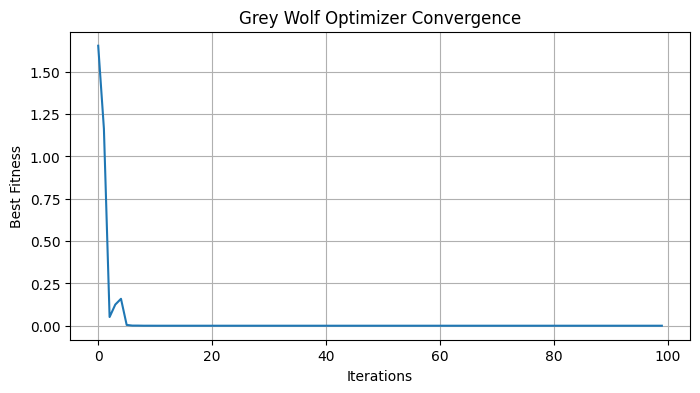

In [1]:

import numpy as np
import matplotlib.pyplot as plt

def objective_function(x):
    return np.sum(x ** 2)

def grey_wolf_optimizer(N=20, D=2, MaxIter=100, x_min=-10, x_max=10):

    X = np.random.uniform(x_min, x_max, (N, D))
    fitness = np.array([objective_function(wolf) for wolf in X])

    alpha = X[np.argmin(fitness)].copy()
    beta = X[np.argsort(fitness)[1]].copy()
    delta = X[np.argsort(fitness)[2]].copy()

    convergence = []

    for t in range(MaxIter):

        a = 2 - 2 * (t / MaxIter)

        for i in range(N):

            positions = []

            for leader in [alpha, beta, delta]:

                r1 = np.random.rand(D)
                r2 = np.random.rand(D)

                A = 2 * a * r1 - a
                C = 2 * r2

                distance = np.abs(C * leader - X[i])
                new_position = leader - A * distance

                positions.append(new_position)

            X[i] = np.mean(positions, axis=0)
            X[i] = np.clip(X[i], x_min, x_max)

            fitness[i] = objective_function(X[i])

        sorted_indices = np.argsort(fitness)

        alpha = X[sorted_indices[0]].copy()
        beta = X[sorted_indices[1]].copy()
        delta = X[sorted_indices[2]].copy()

        convergence.append(objective_function(alpha))

    return alpha, objective_function(alpha), convergence


# Run Grey Wolf Optimizer
best_solution, best_fitness, convergence = grey_wolf_optimizer(
    N=20,
    D=2,
    MaxIter=100,
    x_min=-10,
    x_max=10
)

print("Best Solution:", best_solution)
print("Best Fitness:", best_fitness)

# Convergence Graph
plt.figure(figsize=(8, 4))
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Grey Wolf Optimizer Convergence")
plt.grid(True)
plt.show()
